# Sachs: biological ground-truth evaluation


Uses the 17-arc Sachs reference. Tuned and untuned arms remain separate; F0.5 emphasizes precision. Additional metrics are in the supplementary Sachs notebook.


In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "experiments/run_model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the repository.")
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "experiments")]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()
th.ensure_output_dirs("sachs")


## Tuned and untuned performance


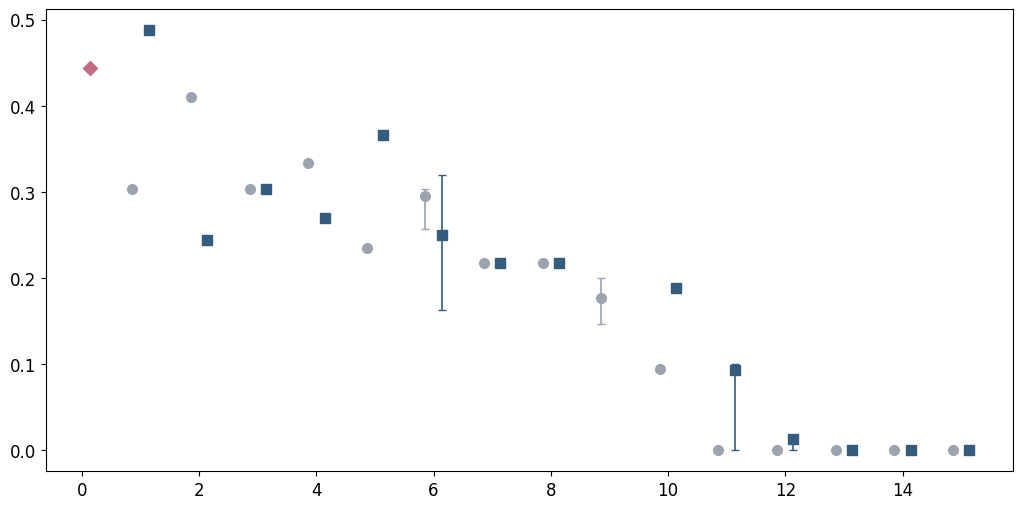

In [2]:
import sachs_table
from matplotlib.lines import Line2D

sachs_runs = sachs_table.load()
sachs_summary = (
    sachs_runs.groupby(["base", "arm"], observed=True)["fbeta"]
    .agg(
        mean="mean",
        lower=lambda x: x.quantile(0.25),
        upper=lambda x: x.quantile(0.75),
    )
    .reset_index()
)
models = (
    sachs_summary.groupby("base", observed=True)["mean"]
    .mean()
    .sort_values(ascending=False)
    .index.tolist()
)
x = np.arange(len(models), dtype=float)
fig_sachs, ax = plt.subplots(figsize=(max(12, 0.78 * len(models)), 6))
arm_style = {"untuned": (-0.14, "o", "#9CA3AF"), "tuned": (0.14, "s", "#355C7D")}
for arm, (offset, marker, base_color) in arm_style.items():
    rows = sachs_summary[sachs_summary.arm.eq(arm)].set_index("base")
    for index, model in enumerate(models):
        if model not in rows.index:
            continue
        row = rows.loc[model]
        is_reg = model == "PRISM"
        color = "#C06C84" if is_reg else base_color
        point_marker = "D" if is_reg else marker
        ax.errorbar(
            x[index] + offset,
            row["mean"],
            yerr=np.asarray(
                [
                    [max(0.0, row["mean"] - row["lower"])],
                    [max(0.0, row["upper"] - row["mean"])],
                ]
            ),
            fmt=point_marker,
            linestyle="none",
            color=color,
            ecolor=color,
            markersize=7,
            capsize=3,
            elinewidth=1.2,
        )


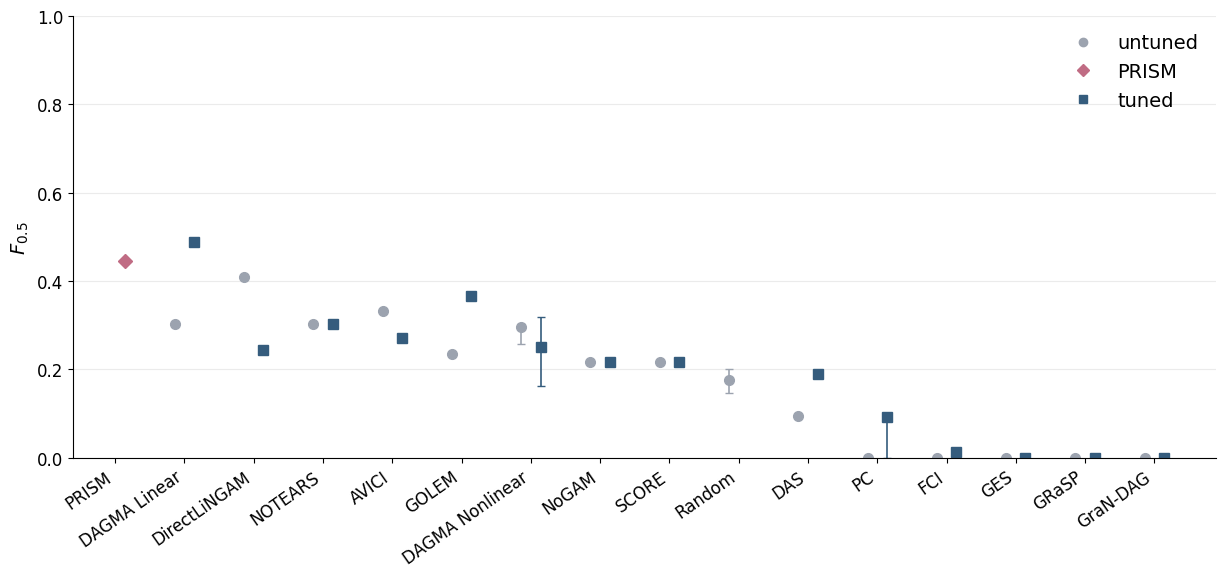

In [3]:
ax.set_xticks(x, [th.model_label(model) for model in models], rotation=35, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("$F_{0.5}$")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(
    handles=[
        Line2D([0], [0], marker="o", linestyle="none", color="#9CA3AF", label="untuned"),
        Line2D(
            [0],
            [0],
            marker="D",
            linestyle="none",
            color="#C06C84",
            label="PRISM",
        ),
        Line2D([0], [0], marker="s", linestyle="none", color="#355C7D", label="tuned"),
    ],
    frameon=False,
    loc="upper right",
)
ax.spines[["top", "right"]].set_visible(False)
fig_sachs.tight_layout()
sachs_pdf = th.save_pdf(fig_sachs, "robustness_f05_sachs.pdf")
display(fig_sachs)
plt.close(fig_sachs)


## Result tables


In [4]:
sachs_long, sachs_wide = sachs_table.build()
sachs_clean = sachs_long.drop(columns=[c for c in sachs_long if c.startswith("_")])
sachs_clean["Modelo"] = sachs_clean["Modelo"].map(th.model_label)
sachs_untuned = sachs_clean[sachs_clean["Braço"].eq("untuned")].copy()
display(sachs_clean)


,Modelo,Braço,N,F0.5,Precisão,Recall,F1,SHD
0,DAGMA Linear,untuned,15,0.303 ± 0.000,0.500 ± 0.000,0.118 ± 0.000,0.190 ± 0.000,15.0 ± 0.0
1,DAGMA Linear,tuned,15,0.488 ± 0.000,0.667 ± 0.000,0.235 ± 0.000,0.348 ± 0.000,13.0 ± 0.0
2,PRISM,tuned,15,0.444 ± 0.000,0.571 ± 0.000,0.235 ± 0.000,0.333 ± 0.000,14.0 ± 0.0
3,GOLEM,untuned,15,0.235 ± 0.000,0.235 ± 0.000,0.235 ± 0.000,0.235 ± 0.000,21.0 ± 0.0
4,GOLEM,tuned,15,0.366 ± 0.000,0.500 ± 0.000,0.176 ± 0.000,0.261 ± 0.000,14.0 ± 0.0
5,NOTEARS,untuned,15,0.303 ± 0.000,0.500 ± 0.000,0.118 ± 0.000,0.190 ± 0.000,15.0 ± 0.0
6,NOTEARS,tuned,15,0.303 ± 0.000,0.500 ± 0.000,0.118 ± 0.000,0.190 ± 0.000,15.0 ± 0.0
7,AVICI,untuned,15,0.333 ± 0.000,0.429 ± 0.000,0.176 ± 0.000,0.250 ± 0.000,15.0 ± 0.0
8,AVICI,tuned,15,0.270 ± 0.000,0.400 ± 0.000,0.118 ± 0.000,0.182 ± 0.000,15.0 ± 0.0
9,DAGMA Nonlinear,untuned,15,0.296 ± 0.104,0.451 ± 0.166,0.125 ± 0.044,0.196 ± 0.068,14.9 ± 0.7


## Reference network

The scoring reference has 11 variables and 17 directed edges.


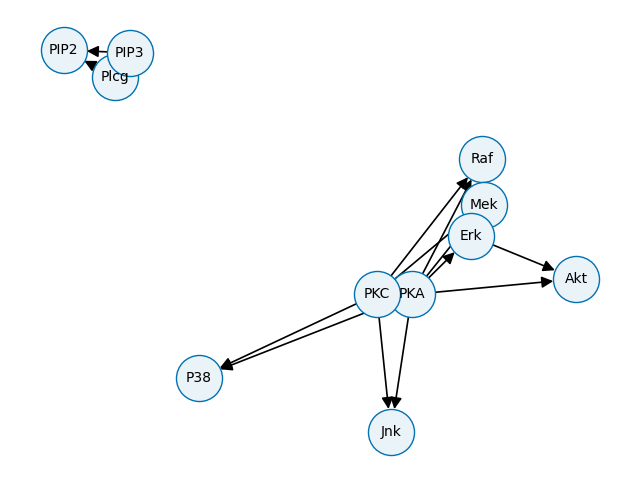

In [5]:
import networkx as nx
from condition_data import load_sample

with load_sample("sachs", "sachs_cd3cd28") as data:
    labels = list(map(str, data["col_names"]))
    reference = data["true_adj"]
graph = nx.relabel_nodes(nx.from_numpy_array(reference, create_using=nx.DiGraph), dict(enumerate(labels)))
positions = nx.spring_layout(graph, seed=42)
fig, ax = plt.subplots(figsize=(8, 6))
nx.draw_networkx(graph, pos=positions, ax=ax, node_color="#EAF3F8", edgecolors="#0072B2",
                 node_size=1100, arrowsize=17, font_size=10, width=1.2)
ax.axis("off")
th.save_pdf(fig, "reference_network.pdf")
display(fig)
plt.close(fig)
